In [1]:
import numpy as np
import sys
import os

sys.path.append(os.path.abspath(".."))

from class_particle_filter import AuxiliaryParticleFilter
from simulations import system_simulation
from plot import plot_results, plot_sorted_weights

En este notebook se presentan una serie de ejemplos lineales. Para cada caso se realiza el filtrado para el Auxiliary Particle Filter con y sin re-muestreo.

# MODELO DE ESPACIO EN ESTADOS

Para todos los casos, se define un sistema lineal y Gaussiano.

- Ecuación de estado:

$$
x_t = A x_{t-1} + w_t, \;\;\; w_t \sim N(0,Q)
$$

- Ecuación de medición

$$
y_t = H x_t + v_t, \;\;\; v_t \sim N(0,R)
$$

Para cada caso, se definirán la matriz transición de estados (A), la matriz observación (H), la matriz covarianza de la ecuación de estado (Q) y la matriz covarianza de la ecuación de medición (R) 

### Ejemplo 2D -> Observación 1D
$$
A = \begin{bmatrix}
1 &1 \\
0 &1
\end{bmatrix}
\;\;
H = \begin{bmatrix}
1 &0 
\end{bmatrix}
\;\;
Q = \begin{bmatrix}
0.1 &0 \\
0 &0.01
\end{bmatrix}
\;\;
R = \begin{bmatrix}
0.5 
\end{bmatrix}
$$

In [3]:
# Modelo lineal 2D -> observación 1D

A = np.array([
    [1. , 1.],
    [0. , 1.]
])

H = np.array([
    [1., 0.]
])

Q = np.array([
    [0.1, 0.0],
    [0.0, 0.01]
])

R = np.array([[0.5]])

def f(x):
    return A @ x

def h(x):
    return H @ x

In [4]:
# Simulacion
T = 50
x0 = np.array([0.0, 0.0])

x_true, y_obs = system_simulation(f, h, Q, R, x0, T)

### Bootstrap Filter

- Con re-muestreo

In [5]:
# Inicializacion Auxiliary Particle Filter
apf_resample = AuxiliaryParticleFilter(
    N=1000,
    state_transition=f,
    measurement_function=h,
    Q=Q,
    R=R
)

apf_resample.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

In [6]:
# Ejecucion filtro de partíulcas con re-muestreo
est = apf_resample.run_filter(y_obs, resample_threshold=500)

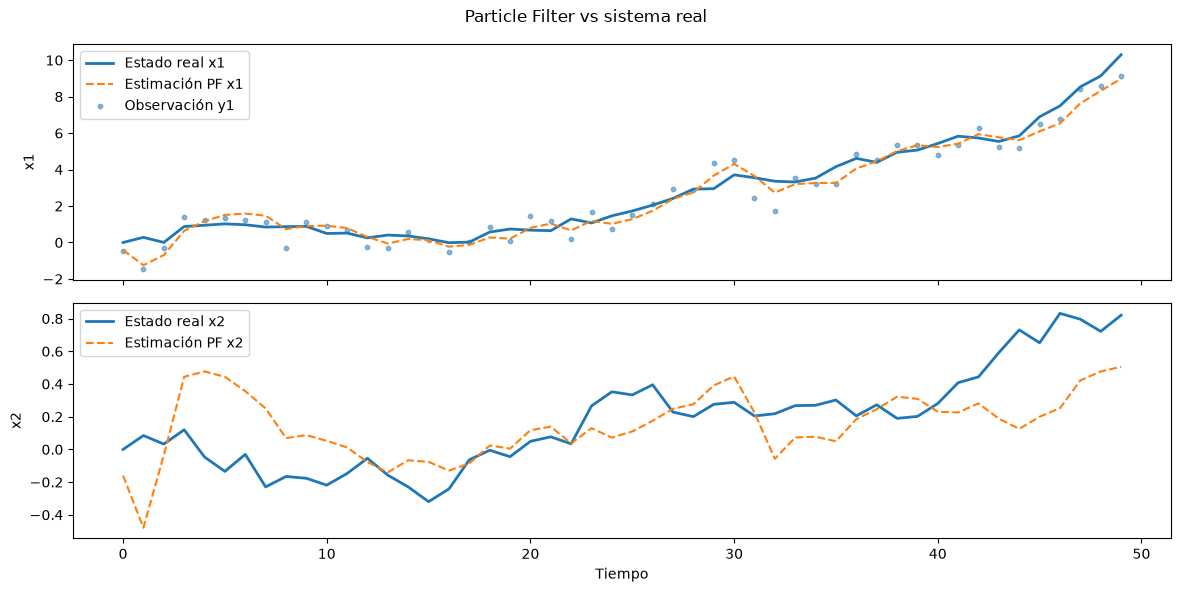

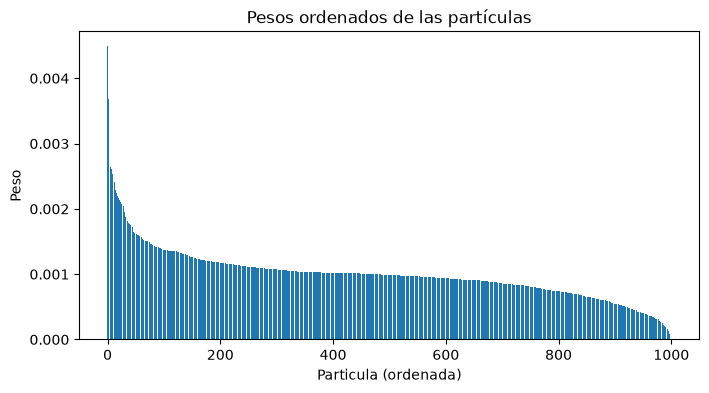

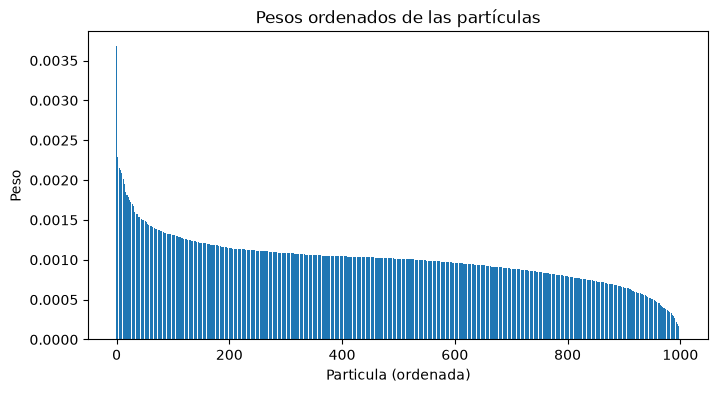

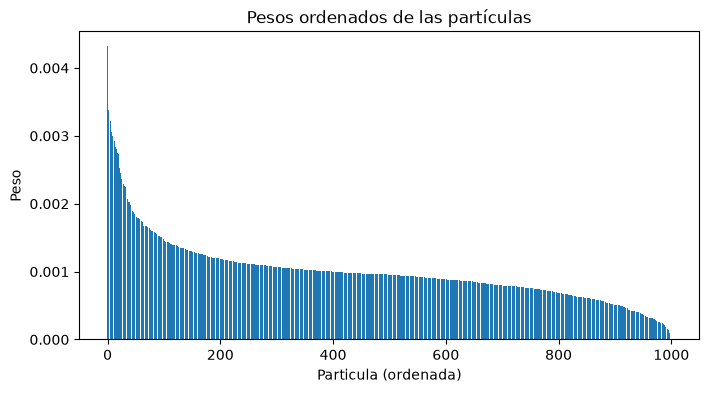

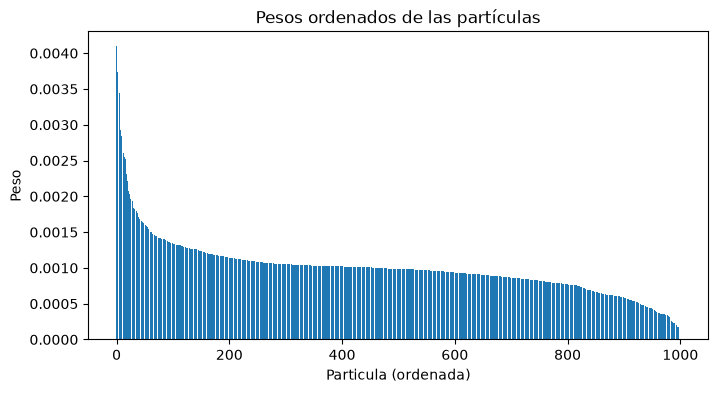

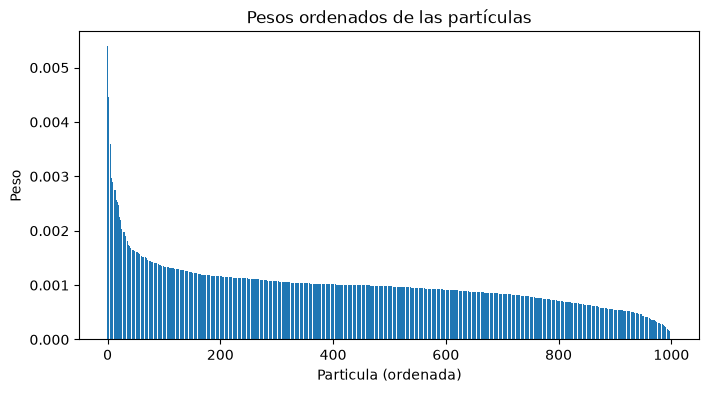

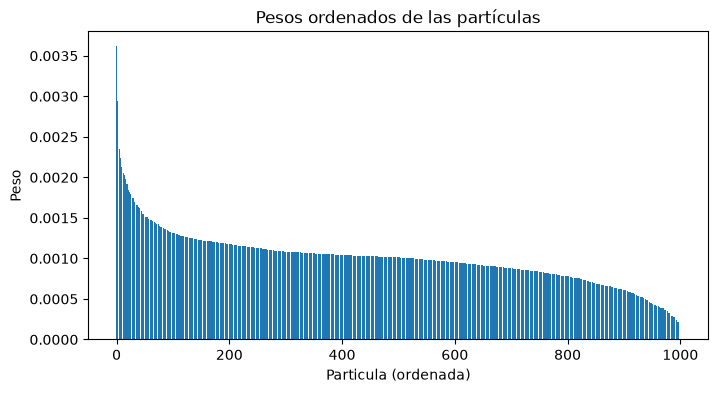

In [7]:
# Plotear resultados
x_est = est["estimates"]
weights = est["weights"]

plot_results(x_true, y_obs, x_est)

for i in [0, 11, 22, 33, 44, 49]:
    plot_sorted_weights(weights[i])

- Sin re-muestreo

In [8]:
# Inicializacion Auxiliary Particle Filter
apf_no_resample = AuxiliaryParticleFilter(
    N=1000,
    state_transition=f,
    measurement_function=h,
    Q=Q,
    R=R
)

apf_no_resample.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

In [9]:
# Ejecucion filtro de partíulcas sin re-muestreo
est = apf_no_resample.run_filter(y_obs)

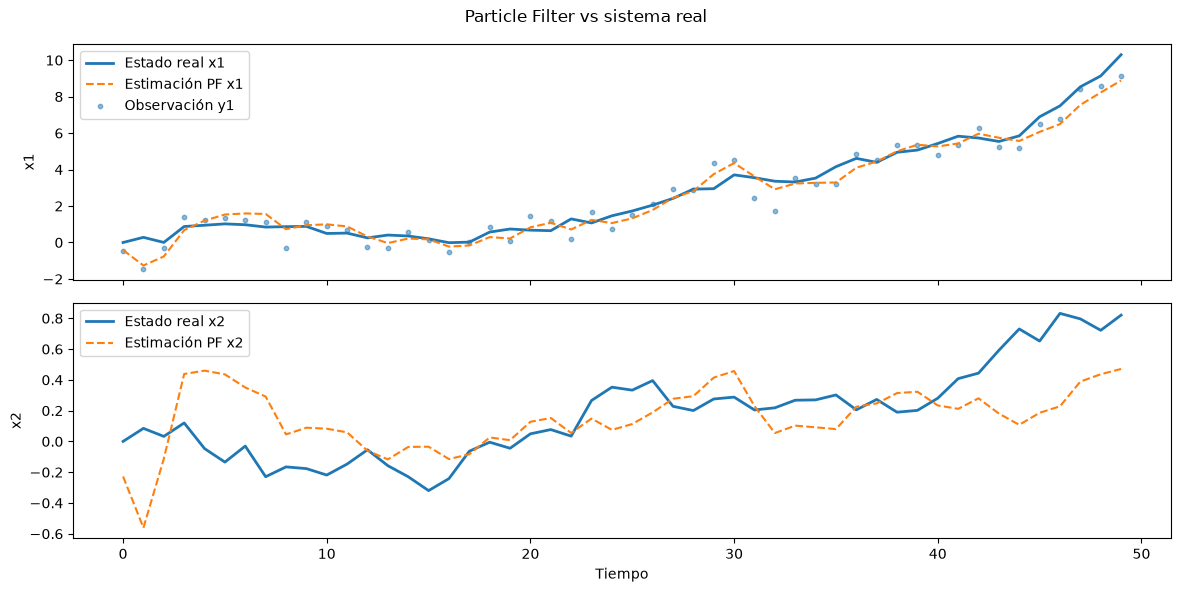

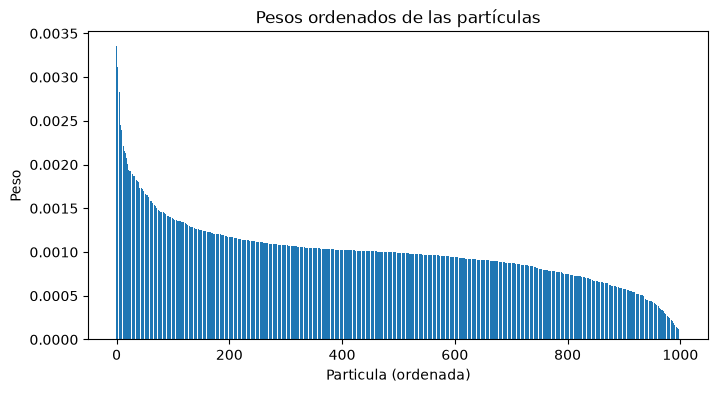

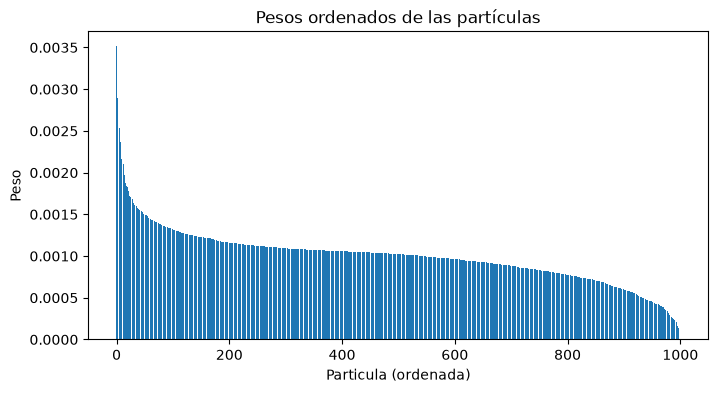

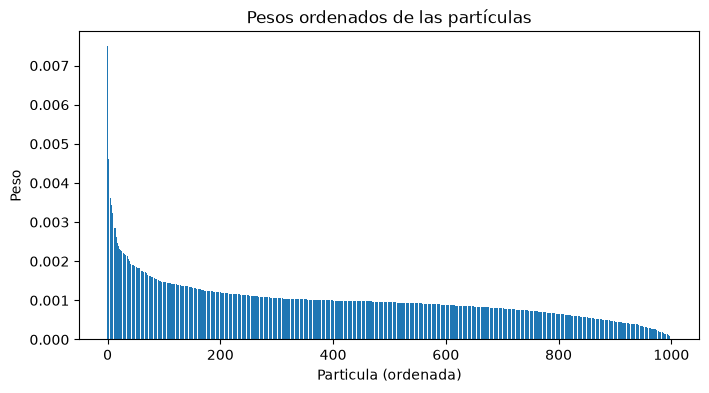

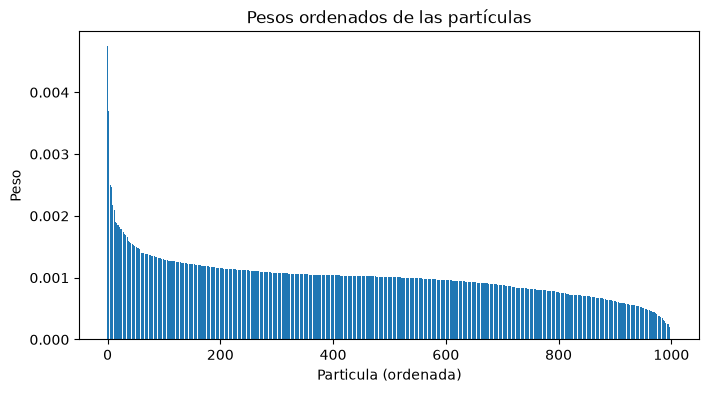

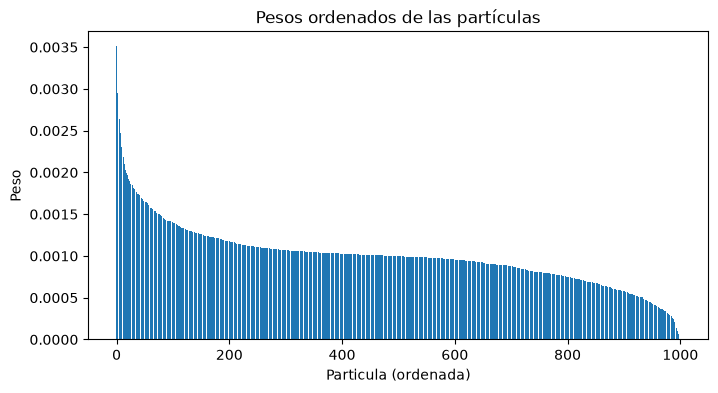

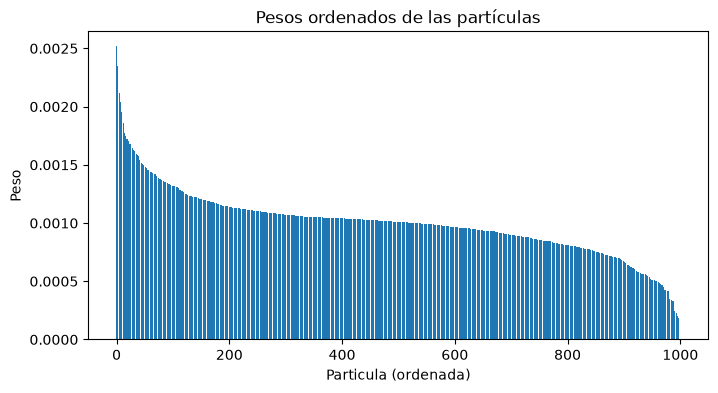

In [12]:
# Plotear resultados
x_est = est["estimates"]
weights = est["weights"]

plot_results(x_true, y_obs, x_est)

for i in [0, 11, 22, 33, 44, 49]:
    plot_sorted_weights(weights[i])

### Ejemplo 2D -> Observación 2D

$$
A = \begin{bmatrix}
1 &1 \\
0 &1
\end{bmatrix}
\;\;
H = \begin{bmatrix}
1 &0 \\
0 &1
\end{bmatrix}
\;\;
Q = \begin{bmatrix}
0.1 &0 \\
0 &0.01
\end{bmatrix}
\;\;
R = \begin{bmatrix}
0.5 &0 \\
0 &0.2
\end{bmatrix}
$$

In [13]:
# Definicion sistema

A = np.array([
    [1., 1.],
    [0., 1.]
])

H = np.eye(2)

Q = np.array([
    [0.1, 0.0],
    [0.0, 0.01]
])

R = np.array([
    [0.5, 0.0],
    [0.0, 0.2]
])

def f(x):
    return A @ x

def h(x):
    return H @ x

In [14]:
# Simulacion
T = 50
x0 = np.array([0.0, 0.0])

x_true, y_obs = system_simulation(f, h, Q, R, x0, T)

- Con re-muestreo

In [15]:
# Inicializacion Auxiliary Particle Filter
apf_resample = AuxiliaryParticleFilter(
    N=1000,
    state_transition=f,
    measurement_function=h,
    Q=Q,
    R=R
)

apf_resample.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

In [16]:
# Ejecucion filtro de particulas con re-muestreo
est = apf_resample.run_filter(y_obs, resample_threshold=500)

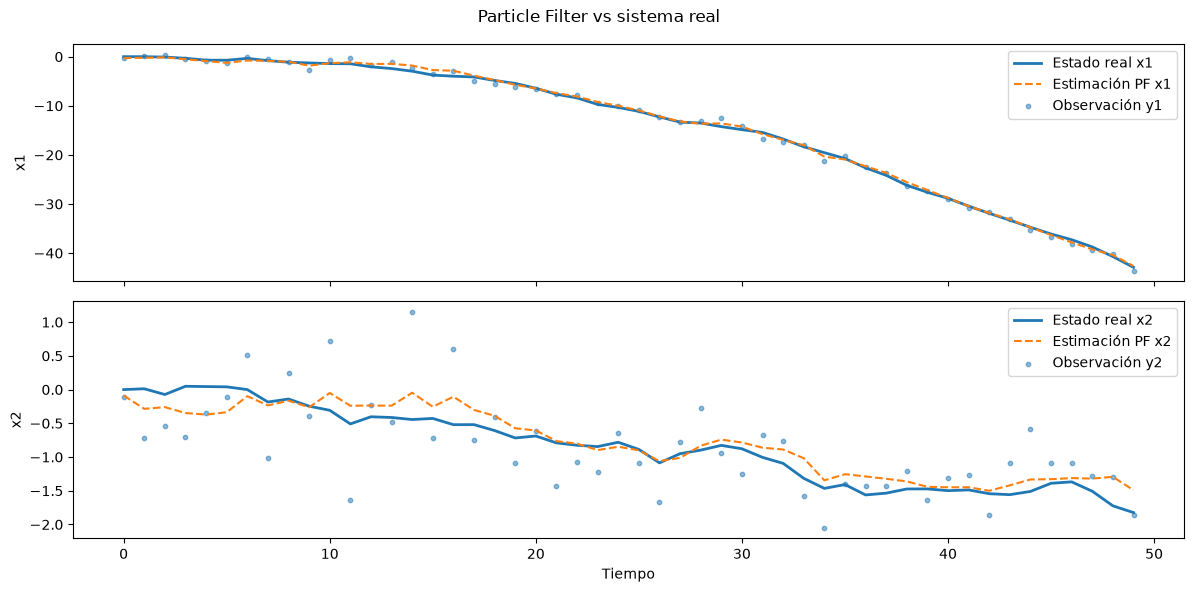

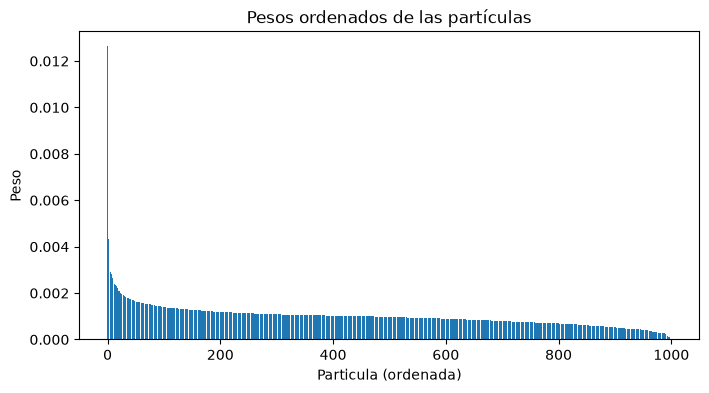

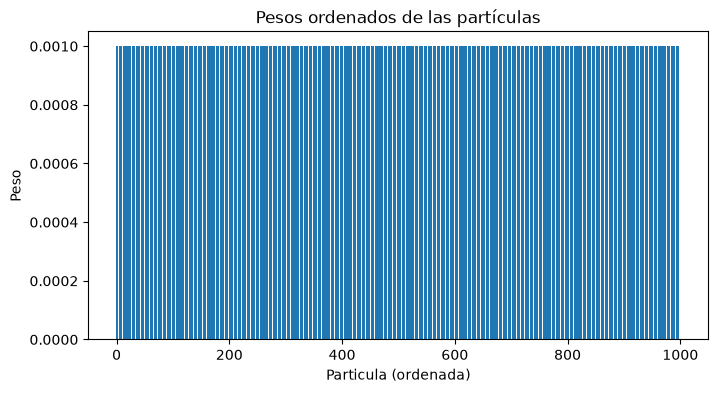

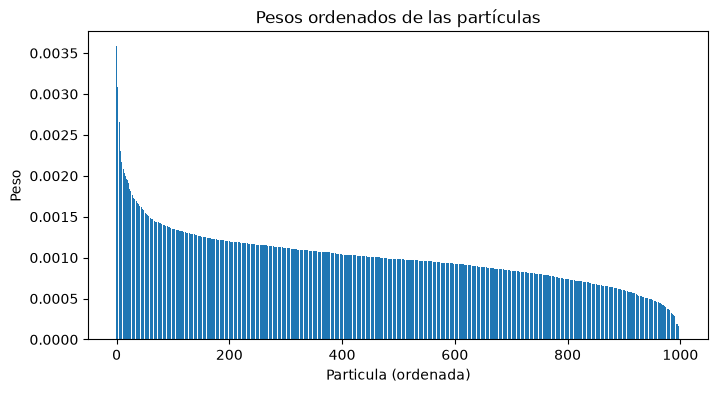

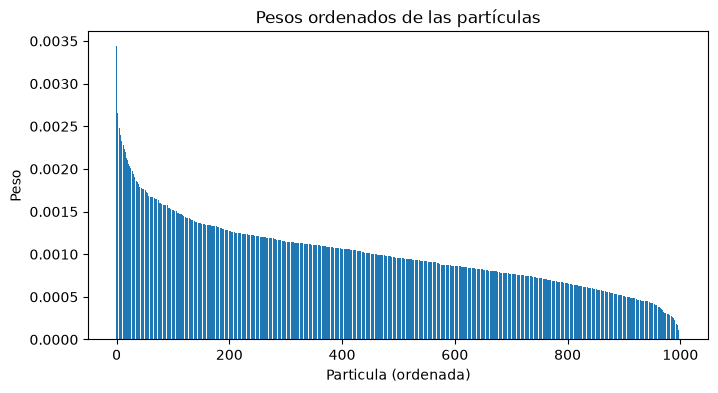

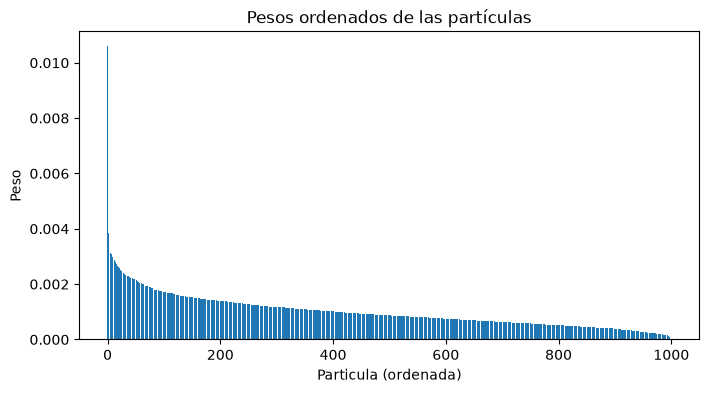

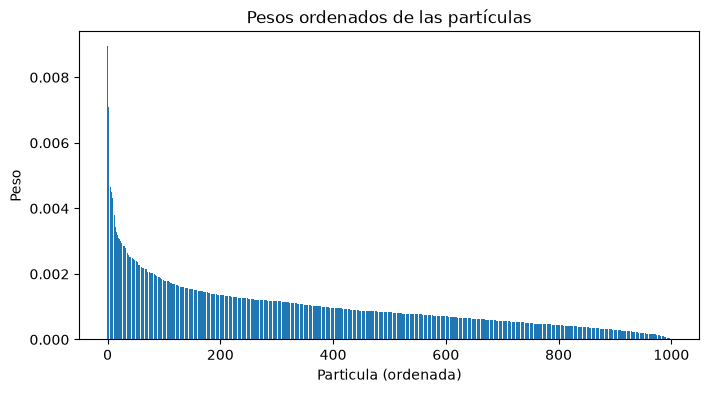

In [17]:
# Plotear resultados
x_est = est["estimates"]
weights = est["weights"]

plot_results(x_true, y_obs, x_est)

for i in [0, 11, 22, 33, 44, 49]:
    plot_sorted_weights(weights[i])

- Sin re-muestreo

In [18]:
# Inicializacion Auxiliary Particle Filter
apf_no_resample = AuxiliaryParticleFilter(
    N=1000,
    state_transition=f,
    measurement_function=h,
    Q=Q,
    R=R
)

apf_no_resample.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

In [19]:
# Ejecucion filtro de particulas sin re-muestreo
est = apf_no_resample.run_filter(y_obs)

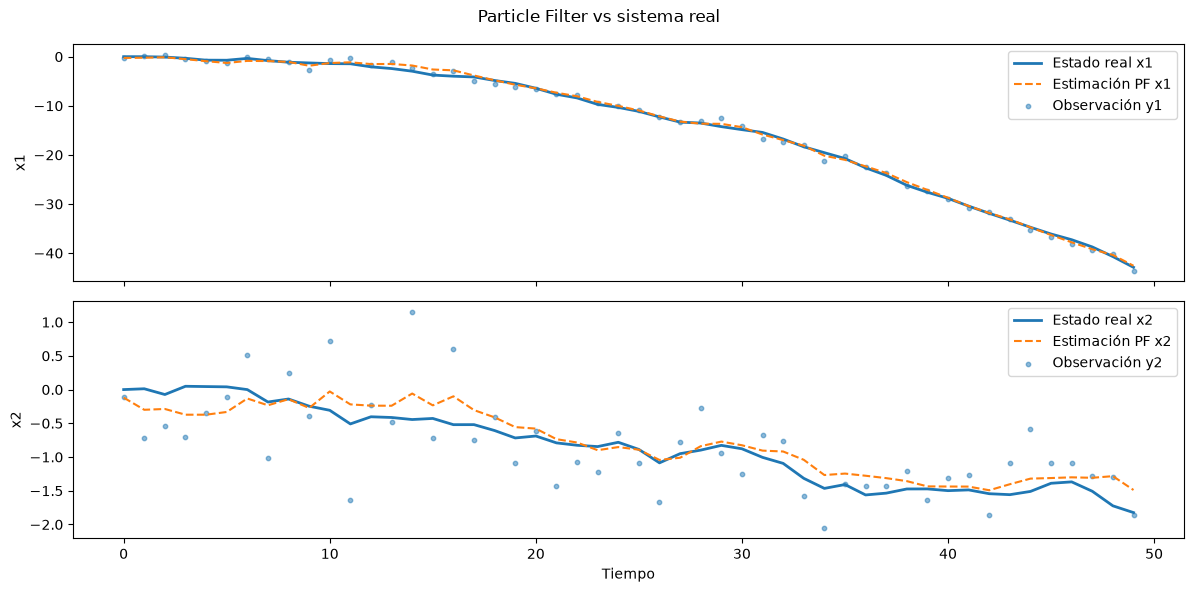

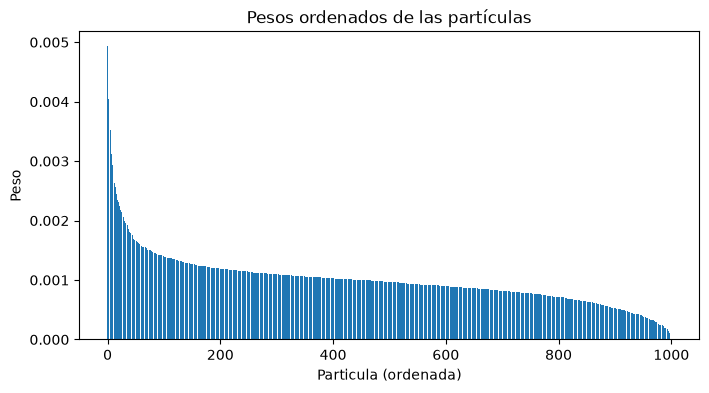

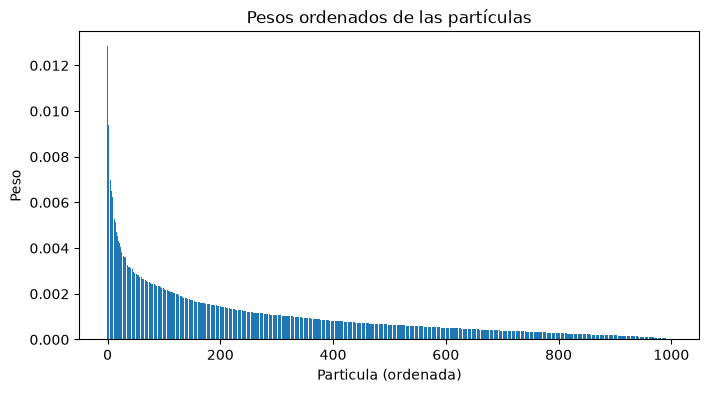

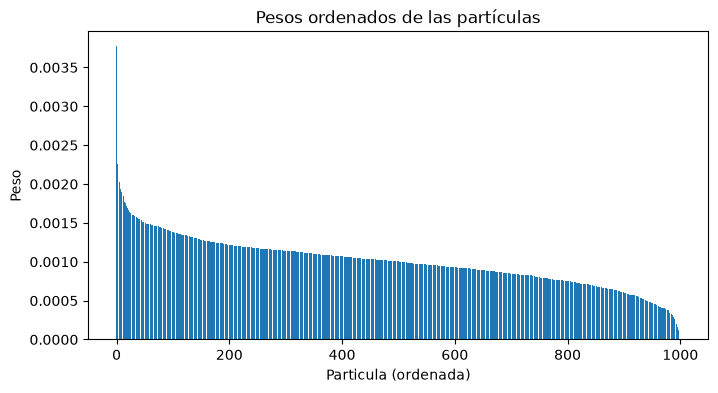

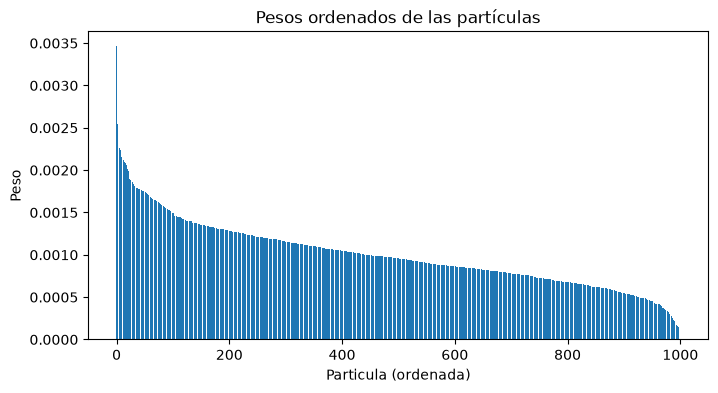

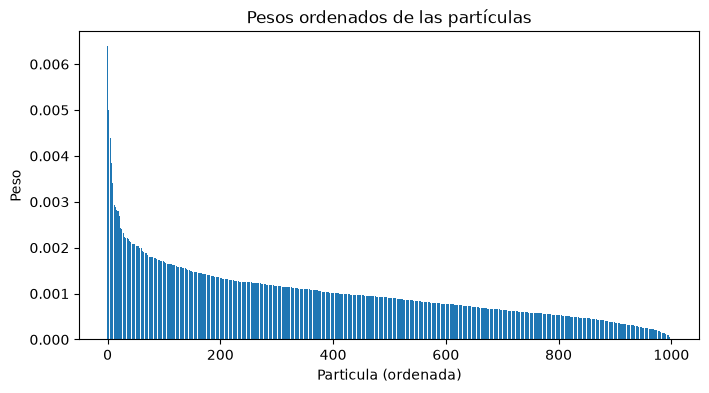

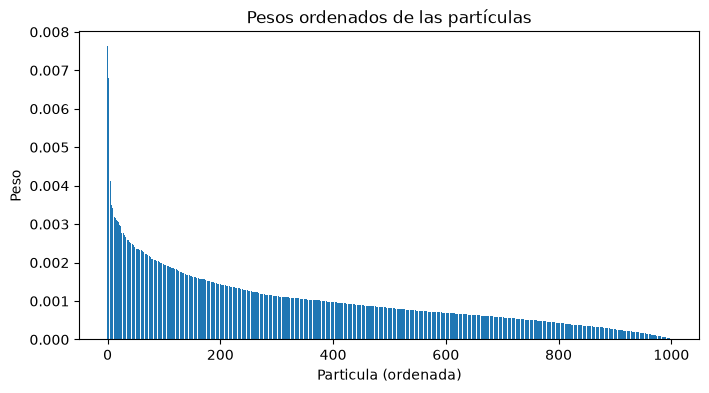

In [20]:
# Plotear resultados
x_est = est["estimates"]
weights = est["weights"]

plot_results(x_true, y_obs, x_est)

for i in [0, 11, 22, 33, 44, 49]:
    plot_sorted_weights(weights[i])